# Assignment 6: lexical/character phishing ensemble

Original notebook using actual project outputs. The historical test set has been seen before: this is an exploratory extension. Weight selection uses a separate inner validation split. Run `experiment.py` explicitly to retrain; this notebook inspects and verifies results.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, average_precision_score, roc_curve, precision_recall_curve
HERE=Path.cwd() if (Path.cwd()/'protocol.json').exists() else Path.cwd()/'phishguard-ai/assignment6'
r=json.loads((HERE/'results/metrics.json').read_text())
p=np.load(HERE/'results/predictions.npz')
charts=HERE/'charts'; charts.mkdir(exist_ok=True)
print(r['source']); print(r['dataset']); print(r['split']); print(r['checks'])
assert all(r['checks'].values())
assert not set(p['source_id']) & set(p['train_source_id'])

{'url': 'https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset', 'version': 1, 'license': 'CC0: Public Domain', 'sha256': 'd83ce942075dd63ed4d11560cfdcd9d512caa3d680e292f22cab484e8f074d01'}
{'raw_rows': 651191, 'raw_columns': ['url', 'type'], 'raw_classes': {'benign': 428103, 'defacement': 96457, 'phishing': 94111, 'malware': 32520}, 'missing': {'url': 0, 'type': 0}, 'raw_duplicates': 10066, 'invalid_binary_rows': 4175, 'conflicting_rows_removed': 7895, 'canonical_duplicates_removed': 258, 'retained': 509886, 'classes': {'benign': 420396, 'phishing': 89490}, 'feature_count': 19}
{'outer_train': 407908, 'inner_fit': 326328, 'inner_validation': 81580, 'historical_test': 101978, 'domain_overlap': 0, 'test_positive': 17898, 'test_negative': 84080}
{'feature_schema_matches': True, 'source_hash_matches': True, 'outer_domains_disjoint': True, 'inner_domains_disjoint': True, 'baseline_probabilities_reproduced': True, 'test_not_used_for_weight_selection': True}


## Rationale and protocol
Counts and lengths lose local character order. A sparse character classifier supplies a complementary representation. The baseline is the existing Logistic Regression, with Random Forest as the stronger comparator. No LLM, API or GPU is involved. Grouped validation chooses one of three weights. The test set never selects the weight or threshold.

In [2]:
print(json.dumps(r['protocol'],indent=2))
cols=['accuracy','precision','recall','f1','fpr','fnr','average_precision','roc_auc']
table=pd.DataFrame({k:{c:m[c] for c in cols} for k,m in r['test'].items()}).T
display(table)
for name,key in [('lexical_random_forest','lexical'),('character_linear','character'),('hybrid','hybrid')]:
 assert np.isclose(r['test'][name]['f1'],f1_score(p['truth'],p[key]>=.5))
 assert np.isclose(r['test'][name]['average_precision'],average_precision_score(p['truth'],p[key]))
print('F1 and AP recompute from actual saved predictions.')

{
  "declared_date": "2026-10-22",
  "question": "Does combining a lexical Random Forest with a URL character-pattern classifier improve phishing F1 and false-positive rate relative to the lexical baseline?",
  "primary_metric": "phishing F1 at threshold 0.5",
  "secondary_metrics": [
    "precision",
    "recall",
    "false-positive rate",
    "false-negative rate",
    "average precision",
    "ROC-AUC",
    "accuracy"
  ],
  "outer_split": "Reuse the stored domain-disjoint train/test partition. This historical test set has been inspected in earlier work; this extension is exploratory, not a fresh confirmatory test.",
  "inner_split": "First seed-73 StratifiedGroupKFold(n_splits=5) fold within the outer training partition only.",
  "lexical_model": {
    "n_estimators": 150,
    "max_depth": 22,
    "min_samples_leaf": 3,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": 2
  },
  "character_model": {
    "representation": "HashingVectorizer",
    "analyzer": "cha

,accuracy,precision,recall,f1,fpr,fnr,average_precision,roc_auc
lexical_logistic_regression,0.668703,0.324014,0.817130,0.464028,0.362892,0.182870,0.452236,0.805621
lexical_random_forest,0.865824,0.578221,0.870432,0.694855,0.135157,0.129568,0.825600,0.940082
character_linear,0.890202,0.646701,0.825232,0.725139,0.095968,0.174768,0.801201,0.943187
hybrid,0.930269,0.761427,0.877696,0.815438,0.058539,0.122304,0.896434,0.967845


F1 and AP recompute from actual saved predictions.


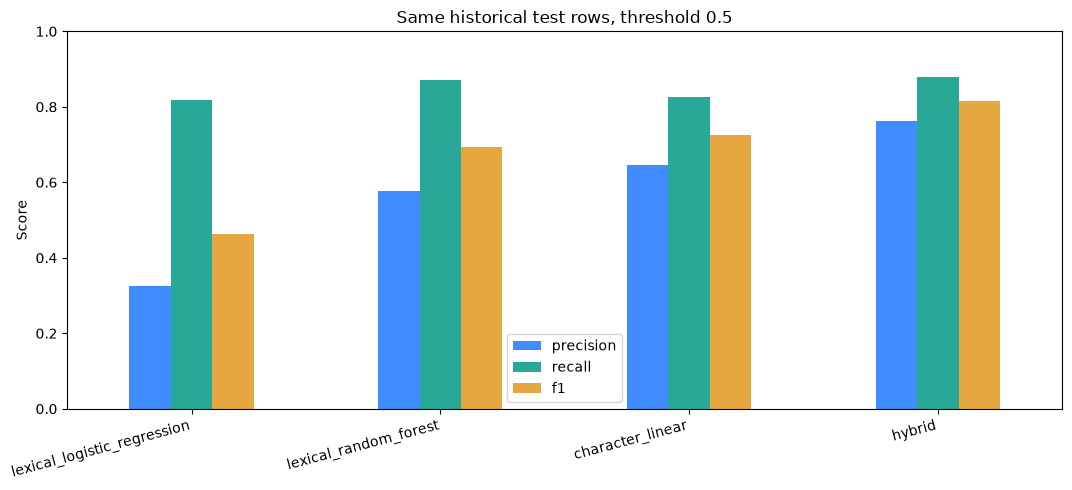

In [3]:
table[['precision','recall','f1']].plot.bar(figsize=(11,5),color=['#408cff','#28a997','#e6a640']); plt.ylim(0,1); plt.ylabel('Score'); plt.title('Same historical test rows, threshold 0.5'); plt.xticks(rotation=15,ha='right'); plt.tight_layout(); plt.savefig(charts/'comparison.png',dpi=180); plt.show()

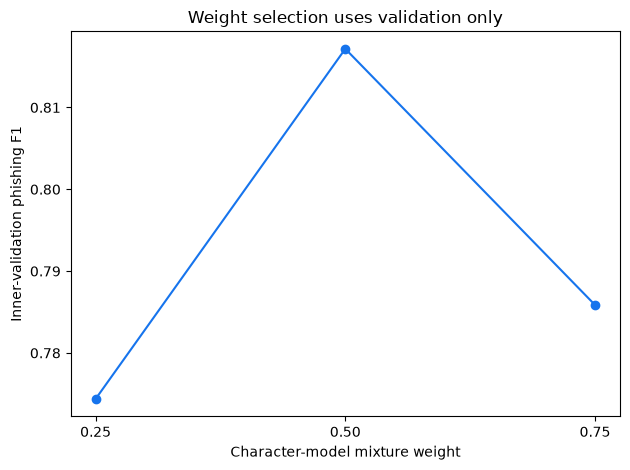

In [4]:
c=r['validation']['candidate_hybrids']; plt.plot([x['character_weight'] for x in c],[x['f1'] for x in c],marker='o',color='#1674ed'); plt.xlabel('Character-model mixture weight'); plt.ylabel('Inner-validation phishing F1'); plt.title('Weight selection uses validation only'); plt.xticks([.25,.5,.75]); plt.tight_layout(); plt.savefig(charts/'validation.png',dpi=180); plt.show()

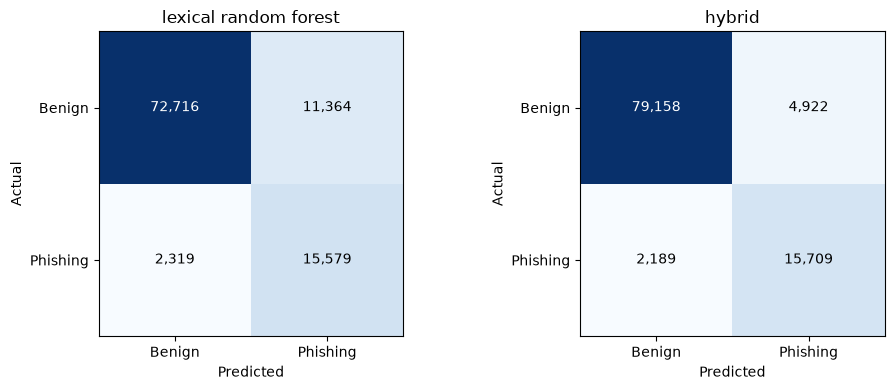

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,name in zip(axes,['lexical_random_forest','hybrid']):
 cm=np.array(r['test'][name]['confusion_matrix']); ax.imshow(cm,cmap='Blues'); ax.set_title(name.replace('_',' ')); ax.set_xticks([0,1],['Benign','Phishing']); ax.set_yticks([0,1],['Benign','Phishing']); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
 for i in range(2):
  for j in range(2): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.tight_layout(); plt.savefig(charts/'confusion.png',dpi=180); plt.show()

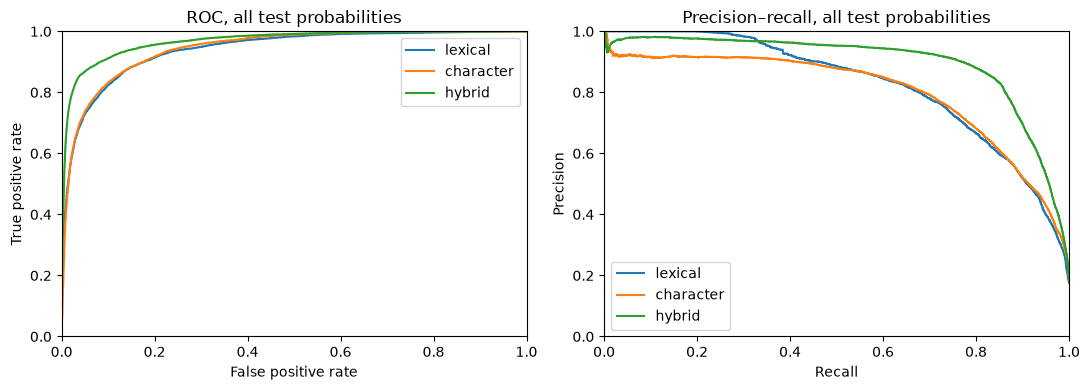

In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for key in ['lexical','character','hybrid']:
 fpr,tpr,_=roc_curve(p['truth'],p[key]); axes[0].plot(fpr,tpr,label=key)
 precision,recall,_=precision_recall_curve(p['truth'],p[key]); axes[1].plot(recall,precision,label=key)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC, all test probabilities'); axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall, all test probabilities')
for ax in axes: ax.legend(); ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.tight_layout(); plt.savefig(charts/'curves.png',dpi=180); plt.show()

In [7]:
display(table[['fpr','fnr','average_precision']])
print('Domain-cluster bootstrap:',r['bootstrap'])
print('Measured timing boundaries:',r['timing'])
base=r['test']['lexical_random_forest']; hybrid=r['test']['hybrid']
print('F1 change (percentage points):',100*(hybrid['f1']-base['f1']))
print('False-positive-rate change (percentage points):',100*(hybrid['fpr']-base['fpr']))

,fpr,fnr,average_precision
lexical_logistic_regression,0.362892,0.182870,0.452236
lexical_random_forest,0.135157,0.129568,0.825600
character_linear,0.095968,0.174768,0.801201
hybrid,0.058539,0.122304,0.896434


Domain-cluster bootstrap: {'unit': 'registrable domain', 'draws': 500, 'groups': 30439, 'f1_difference_95_percentile': [0.030462677258573503, 0.21675511969019726], 'note': 'Conditional, exploratory percentile interval; does not include model-selection/training variability or remove historical-test reuse bias.'}
Measured timing boundaries: {'validation_lexical_fit_seconds': 57.035375999999815, 'validation_character_fit_seconds': 23.631356899997627, 'full_character_fit_seconds': 29.528414699998393, 'character_test_predict_seconds': 6.813023900002008, 'lexical_test_predict_seconds_including_load': 2.322190800001408, 'total_seconds': 174.3464712999994}
F1 change (percentage points): 12.058256735462148
False-positive-rate change (percentage points): -7.661750713606091


## XSS controls and limitations
The local AI transcript previously interpolated query text into innerHTML. The targeted fix uses textContent, independent of prompt-guard state. The new workbench lab tests literal rendering, contextual HTML-text encoding and validation boundaries. Existing SentrySim vulnerable behavior remains intentional.

Hybrid gains are exploratory. Character-only recall/AP are worse than Random Forest, which motivates ablation rather than a blanket claim that text features improve everything. Test reuse, source bias, hashing collisions and a single fitted seed remain limitations. The conditional domain-bootstrap interval excludes model-selection and retraining variability. See submission.md and verification.md.